In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [2]:
class BahdanauAttention(nn.Module):
    """
    Implementasi Bahdanau (Additive) Attention.
    """
    def __init__(self, hidden_dim):
        super(BahdanauAttention, self).__init__()
        self.W_query = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.W_key   = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.v       = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, query, keys):
        """
        query : (batch, hidden_dim)  → decoder hidden state
        keys  : (batch, seq_len, hidden_dim)  → encoder outputs
        """
        # Expand query: (batch, 1, hidden_dim)
        query = query.unsqueeze(1)

        # Hitung energy
        energy = torch.tanh(
            self.W_query(query) + self.W_key(keys)
        )  # (batch, seq_len, hidden_dim)

        # Attention scores
        scores = self.v(energy).squeeze(-1)  # (batch, seq_len)

        # Attention weights
        weights = F.softmax(scores, dim=-1)  # (batch, seq_len)

        # Context vector
        context = torch.bmm(
            weights.unsqueeze(1),  # (batch, 1, seq_len)
            keys                   # (batch, seq_len, hidden_dim)
        ).squeeze(1)               # (batch, hidden_dim)

        return context, weights

In [3]:
class ScaledDotProductAttention(nn.Module):
    """
    Implementasi Scaled Dot-Product Attention (digunakan dalam Transformer).
    """
    def __init__(self, d_k):
        super(ScaledDotProductAttention, self).__init__()
        self.scale = d_k ** 0.5

    def forward(self, Q, K, V, mask=None):
        """
        Q, K, V: (batch, seq_len, d_k)
        """
        # Attention scores
        scores = torch.bmm(Q, K.transpose(1, 2)) / self.scale
        # (batch, seq_len_q, seq_len_k)

        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)

        weights = F.softmax(scores, dim=-1)

        output = torch.bmm(weights, V)
        return output, weights

In [4]:
def visualize_attention(weights, input_tokens, output_tokens=None, title="Attention Weights"):
    """
    Visualisasikan attention weights sebagai heatmap.

    weights      : numpy array (seq_len_out, seq_len_in)
    input_tokens : list of str
    output_tokens: list of str (opsional)
    """
    fig, ax = plt.subplots(figsize=(10, 8))

    sns.heatmap(
        weights,
        xticklabels=input_tokens,
        yticklabels=output_tokens if output_tokens else range(weights.shape[0]),
        cmap="Blues",
        annot=True,
        fmt=".2f",
        ax=ax,
        linewidths=0.5
    )

    ax.set_title(title)
    ax.set_xlabel("Input (Encoder)")
    ax.set_ylabel("Output (Decoder)" if output_tokens else "Timestep")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

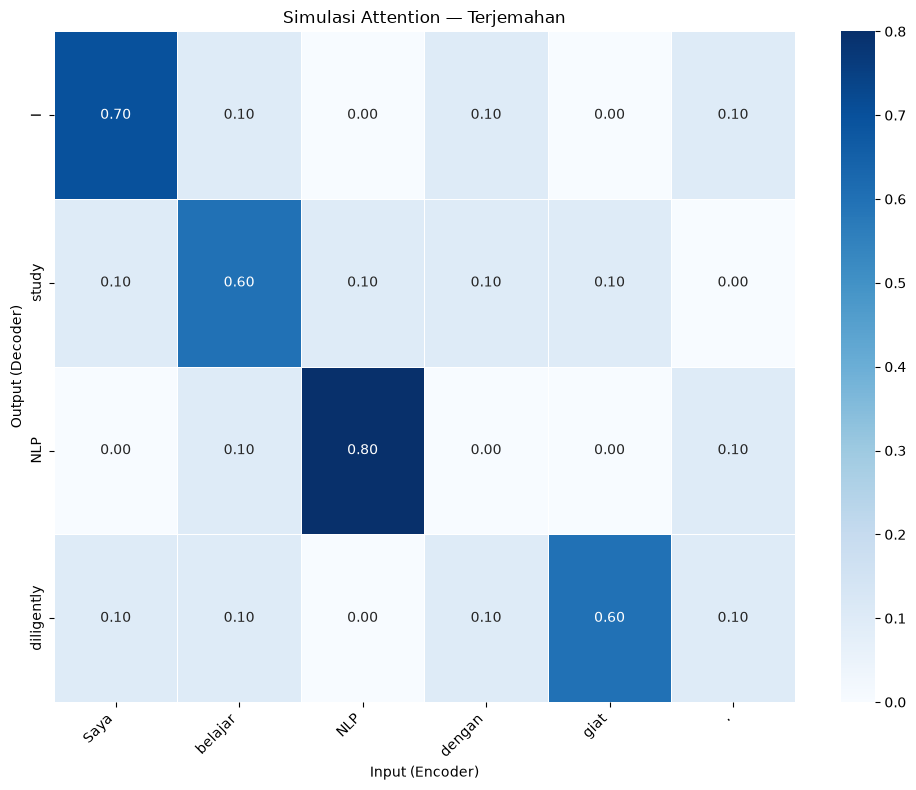

In [5]:
# Simulasi attention sederhana dengan data buatan
# Misalkan: kalimat input 6 token, kalimat output 4 token

input_tokens  = ["Saya", "belajar", "NLP", "dengan", "giat", "."]
output_tokens = ["I", "study", "NLP", "diligently"]

# Buat attention weights contoh (simulasi)
# Baris = output token, Kolom = input token
attention_weights = np.array([
    [0.7, 0.1, 0.0, 0.1, 0.0, 0.1],  # "I"         → fokus ke "Saya"
    [0.1, 0.6, 0.1, 0.1, 0.1, 0.0],  # "study"     → fokus ke "belajar"
    [0.0, 0.1, 0.8, 0.0, 0.0, 0.1],  # "NLP"       → fokus ke "NLP"
    [0.1, 0.1, 0.0, 0.1, 0.6, 0.1],  # "diligently"→ fokus ke "giat"
])

visualize_attention(
    attention_weights,
    input_tokens,
    output_tokens,
    "Simulasi Attention — Terjemahan"
)

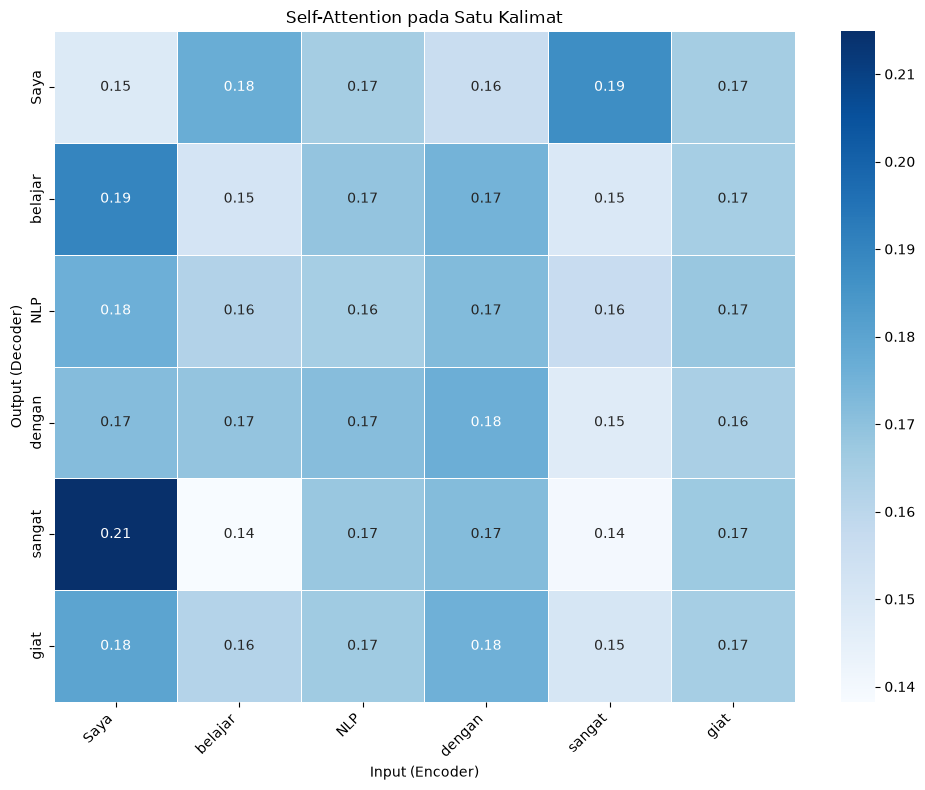

In [6]:
def compute_self_attention(tokens, d_model=8):
    """
    Demonstrasi self-attention sederhana dengan inisialisasi random.
    """
    seq_len = len(tokens)

    # Simulasi embedding (random untuk demonstrasi)
    np.random.seed(42)
    embeddings = np.random.randn(seq_len, d_model)

    # Proyeksi Q, K, V (random weights untuk demonstrasi)
    W_Q = np.random.randn(d_model, d_model) * 0.1
    W_K = np.random.randn(d_model, d_model) * 0.1
    W_V = np.random.randn(d_model, d_model) * 0.1

    Q = embeddings @ W_Q  # (seq_len, d_model)
    K = embeddings @ W_K
    V = embeddings @ W_V

    # Attention scores
    scores = (Q @ K.T) / (d_model ** 0.5)  # (seq_len, seq_len)

    # Softmax
    def softmax(x):
        e_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
        return e_x / e_x.sum(axis=-1, keepdims=True)

    weights = softmax(scores)  # (seq_len, seq_len)
    output = weights @ V       # (seq_len, d_model)

    return weights, output

# Contoh kalimat
sentence = "Saya belajar NLP dengan sangat giat"
tokens = sentence.split()

weights, output = compute_self_attention(tokens)

visualize_attention(
    weights,
    tokens,
    tokens,
    "Self-Attention pada Satu Kalimat"
)

In [7]:
class EncoderLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=False)

    def forward(self, x):
        embedded = self.embedding(x)
        outputs, (hidden, cell) = self.lstm(embedded)
        return outputs, hidden

# Simulasi sederhana: encode kalimat pendek
vocab = {"<PAD>": 0, "saya": 1, "belajar": 2, "nlp": 3, "sangat": 4, "menarik": 5}
VOCAB_SIZE = len(vocab)
EMBED_DIM  = 32
HIDDEN_DIM = 64

encoder = EncoderLSTM(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM)
attention = BahdanauAttention(HIDDEN_DIM)

# Input: "saya belajar nlp sangat menarik"
input_tokens = [vocab.get(t, 0) for t in ["saya", "belajar", "nlp", "sangat", "menarik"]]
input_tensor = torch.LongTensor([input_tokens])

with torch.no_grad():
    encoder_outputs, hidden = encoder(input_tensor)
    context, attn_weights = attention(hidden[-1], encoder_outputs)

print("Encoder output shape  :", encoder_outputs.shape)
print("Attention weights shape:", attn_weights.shape)
print("Attention weights      :", attn_weights.squeeze().numpy().round(4))

Encoder output shape  : torch.Size([1, 5, 64])
Attention weights shape: torch.Size([1, 5])
Attention weights      : [0.2041 0.1968 0.1951 0.2067 0.1973]


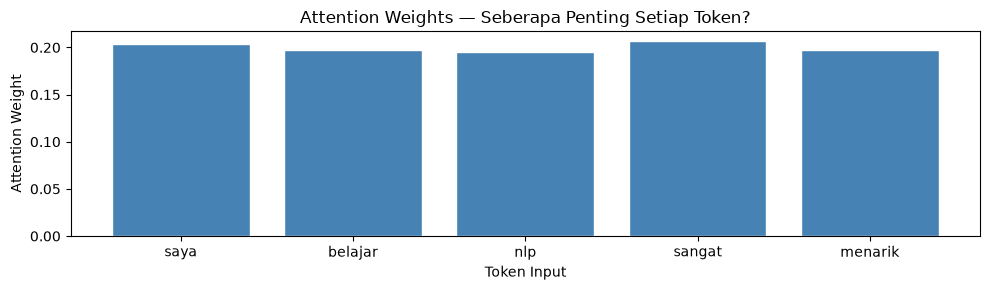

In [8]:
attn_np = attn_weights.squeeze().detach().numpy()
token_labels = ["saya", "belajar", "nlp", "sangat", "menarik"]

plt.figure(figsize=(10, 3))
plt.bar(token_labels, attn_np, color="steelblue", edgecolor="white")
plt.title("Attention Weights — Seberapa Penting Setiap Token?")
plt.xlabel("Token Input")
plt.ylabel("Attention Weight")
plt.tight_layout()
plt.show()

In [9]:
print("PERBANDINGAN: Encoder-Decoder")
print("=" * 60)
print()
print("TANPA ATTENTION:")
print("  Encoder → satu context vector → Decoder")
print("  Masalah: bottleneck pada sequence panjang.")
print("  Semakin panjang input, semakin banyak informasi hilang.")
print()
print("DENGAN ATTENTION:")
print("  Encoder → semua hidden states")
print("  Decoder → pilih hidden state yang relevan pada setiap langkah")
print("  Tidak ada bottleneck — decoder dapat mengakses semua token input.")
print()
print("SELF-ATTENTION (Transformer):")
print("  Setiap token dapat 'melihat' semua token lain dalam kalimat.")
print("  Dapat diparalelkan → jauh lebih cepat dari RNN.")
print("  Fondasi dari BERT, GPT, dan semua model modern. → Modul 3!")

PERBANDINGAN: Encoder-Decoder

TANPA ATTENTION:
  Encoder → satu context vector → Decoder
  Masalah: bottleneck pada sequence panjang.
  Semakin panjang input, semakin banyak informasi hilang.

DENGAN ATTENTION:
  Encoder → semua hidden states
  Decoder → pilih hidden state yang relevan pada setiap langkah
  Tidak ada bottleneck — decoder dapat mengakses semua token input.

SELF-ATTENTION (Transformer):
  Setiap token dapat 'melihat' semua token lain dalam kalimat.
  Dapat diparalelkan → jauh lebih cepat dari RNN.
  Fondasi dari BERT, GPT, dan semua model modern. → Modul 3!
